In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "masbudget").is_dir() else Path.cwd().parent
os.chdir(ROOT)
sys.path[:0] = [str(ROOT), str(ROOT / "experiments")]
import pandas as pd
from IPython.display import Image, display
from lib import load, md_table
import plots
plots.style()
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 4)
%matplotlib inline

# E4-E6 - Utility design, the pacing mechanism and the full factorial

Notes in `experiments/E04_*.md` - `E06_*.md`.

## E4 - Tuned utilities (tuned at tau = 0.2 on the calibration split, evaluated on the evaluation split)

In [2]:
b = load('e04b_eval_summary')
p = b.pivot(index='policy', columns='tau', values='gap_exp')
p['worst'] = p.max(axis=1)
(100 * p.sort_values('worst')).round(2)

tau,0.0,0.02,0.05,0.1,0.2,0.35,0.5,0.75,1.0,worst
policy,,,,,,,,,,
Predictive router,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
MCKP (optimal),0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Pacing (ours) tuned + reserve,0.00,0.00,0.00,0.01,0.06,0.49,0.10,0.00,0.00,0.49
Pacing (ours) tuned,0.00,0.00,0.00,0.01,0.06,1.17,0.10,0.00,0.00,1.17
U2 shadow price tuned + reserve,0.00,0.06,0.01,0.00,0.00,0.30,0.99,1.98,1.98,1.98
U1 quasi-linear tuned + reserve,0.00,0.06,0.01,0.00,0.00,0.09,0.99,1.98,1.98,1.98
U4 marginal ROI tuned + reserve,0.00,0.06,0.01,0.00,0.00,0.09,0.99,1.98,1.98,1.98
U3 Shapley share tuned + reserve,0.00,0.06,0.01,0.00,0.00,0.66,1.55,2.54,2.54,2.54
Static equal quota,0.00,0.71,2.09,1.14,1.42,2.80,0.79,0.24,0.00,2.80


Fixed-parameter utilities tuned at one budget fail at others unless the ledger reserve stops starvation; the pacing utility is within 0.5% of optimal at every budget (1.2% without reserve).

In [3]:
c = load('e04c_lambda_sweep_summary')
pv = c.pivot(index='policy', columns='tau', values='gap_exp')
(100 * pv).round(1)

tau,0.00,0.02,0.05,0.10,0.20,0.35,0.50,0.75,1.00
policy,,,,,,,,,
Cheapest model,0.0,2.1,3.5,5.7,9.8,14.8,15.6,16.4,16.4
MCKP (optimal),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
lambda=1000|False,0.0,2.1,3.5,5.7,9.8,14.8,15.6,16.4,16.4
lambda=1000|True,0.0,2.1,3.5,5.7,9.8,14.8,15.6,16.4,16.4
lambda=100|False,0.0,2.1,3.5,5.7,9.8,14.8,15.6,16.4,16.4
lambda=100|True,0.0,2.1,3.5,5.7,9.8,14.8,15.6,16.4,16.4
lambda=11|False,84.0,75.9,68.1,54.5,28.7,0.1,1.0,2.0,2.0
lambda=11|True,0.0,0.0,0.0,0.0,0.0,0.1,1.0,2.0,2.0
lambda=12|False,7.7,0.7,2.1,4.3,8.5,13.6,14.4,15.3,15.3


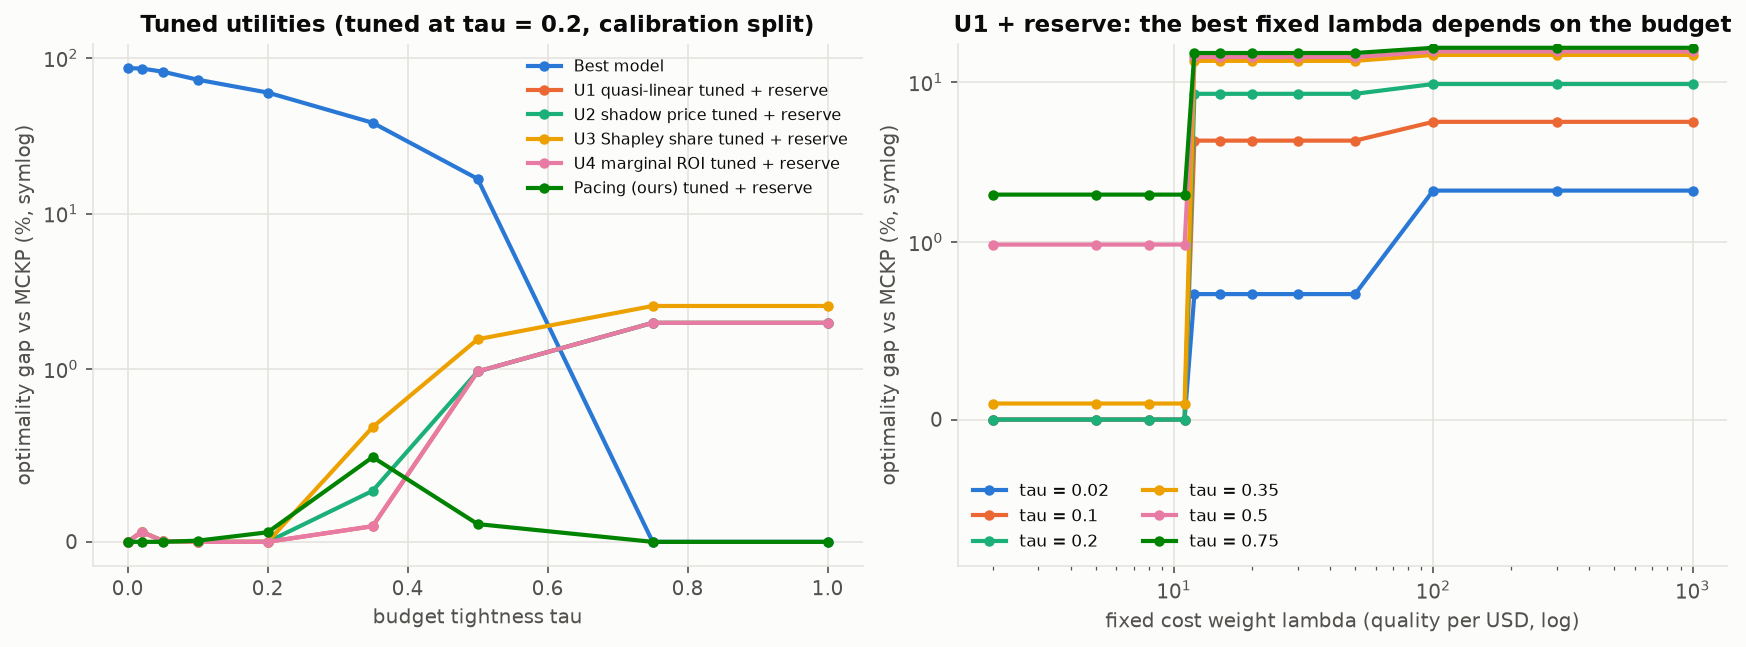

In [4]:
display(Image('experiments/figures/e04_utility_design.png'))

## E5 - Robustness of the pacing price
A: misspecified reference price; B: difficulty-mix shift; C: wrong horizon; D: price floor.

In [5]:
a = load('e05a_summary')
(100 * a[(a.tau == 0.2)].pivot_table(index='scale', columns=['res', 'beta'], values='gap_exp')).round(2)

res     False                      True                   
beta     0.0    2.0    5.0    10.0  0.0   2.0   5.0   10.0
scale                                                     
0.01    60.16  60.16  53.37  39.41  4.44  4.44  3.80  1.83
0.10    60.16  38.58  33.50  18.33  4.44  1.38  0.70  0.43
0.30    28.72  28.72  18.13   7.88  0.00  0.00  0.00  0.00
1.00     8.47   0.07   0.07   0.07  8.47  0.07  0.07  0.07
3.00     8.47   5.77   2.34   1.19  8.47  5.77  2.34  1.19
10.00    9.76   8.70   4.96   2.50  9.76  8.70  4.96  2.50
100.00   9.76   9.76   9.28   5.21  9.76  9.76  9.28  5.21

In [6]:
bb = load('e05b_summary')
p = bb.pivot_table(index='policy', columns='mix', values='gap_exp', aggfunc='max')
(100 * p.sort_values('hard_heavy')).round(2)

mix,easy_heavy,hard_heavy,uniform
policy,,,
MCKP (optimal),0.00,0.00,0.00
Fixed lambda=10 + reserve (tuned),0.50,0.88,1.98
Pacing (beta=5) + reserve,0.52,4.25,0.49
Best model + reserve,1.44,4.25,6.00
Static equal quota,1.58,5.00,2.80
Posted price lambda*_hist + reserve,3.92,18.56,8.47
Pacing (beta=5),2.71,19.52,1.17
Posted price lambda*_hist (beta=0),3.92,34.05,8.47
Posted price lambda*_batch + reserve,3.27,46.54,8.47


In [7]:
dd = load('e05d_summary_calib')
w = dd.groupby(['policy', 'mix']).gap_exp.max().unstack()
w['worst'] = w.max(axis=1)
(100 * w.sort_values('worst')).round(2).head(10)

mix,easy_heavy,hard_heavy,uniform,worst
policy,,,,
floor=0.1|beta=10.0|res=True,0.39,0.35,0.32,0.39
floor=0.2|beta=10.0|res=True,0.39,0.69,0.56,0.69
floor=0.1|beta=5.0|res=True,0.56,0.71,0.59,0.71
floor=0.05|beta=5.0|res=True,0.56,0.28,0.89,0.89
floor=0.05|beta=10.0|res=True,0.39,0.33,0.96,0.96
floor=0.2|beta=5.0|res=True,0.56,0.88,1.09,1.09
floor=0.02|beta=10.0|res=True,0.39,2.86,1.00,2.86
floor=0.01|beta=10.0|res=True,0.39,4.03,1.00,4.03
floor=0.0|beta=10.0|res=True,0.39,4.03,1.00,4.03


Selected on the calibration split: beta = 10, floor 0.1 / (c_max - c_min), reserve on.

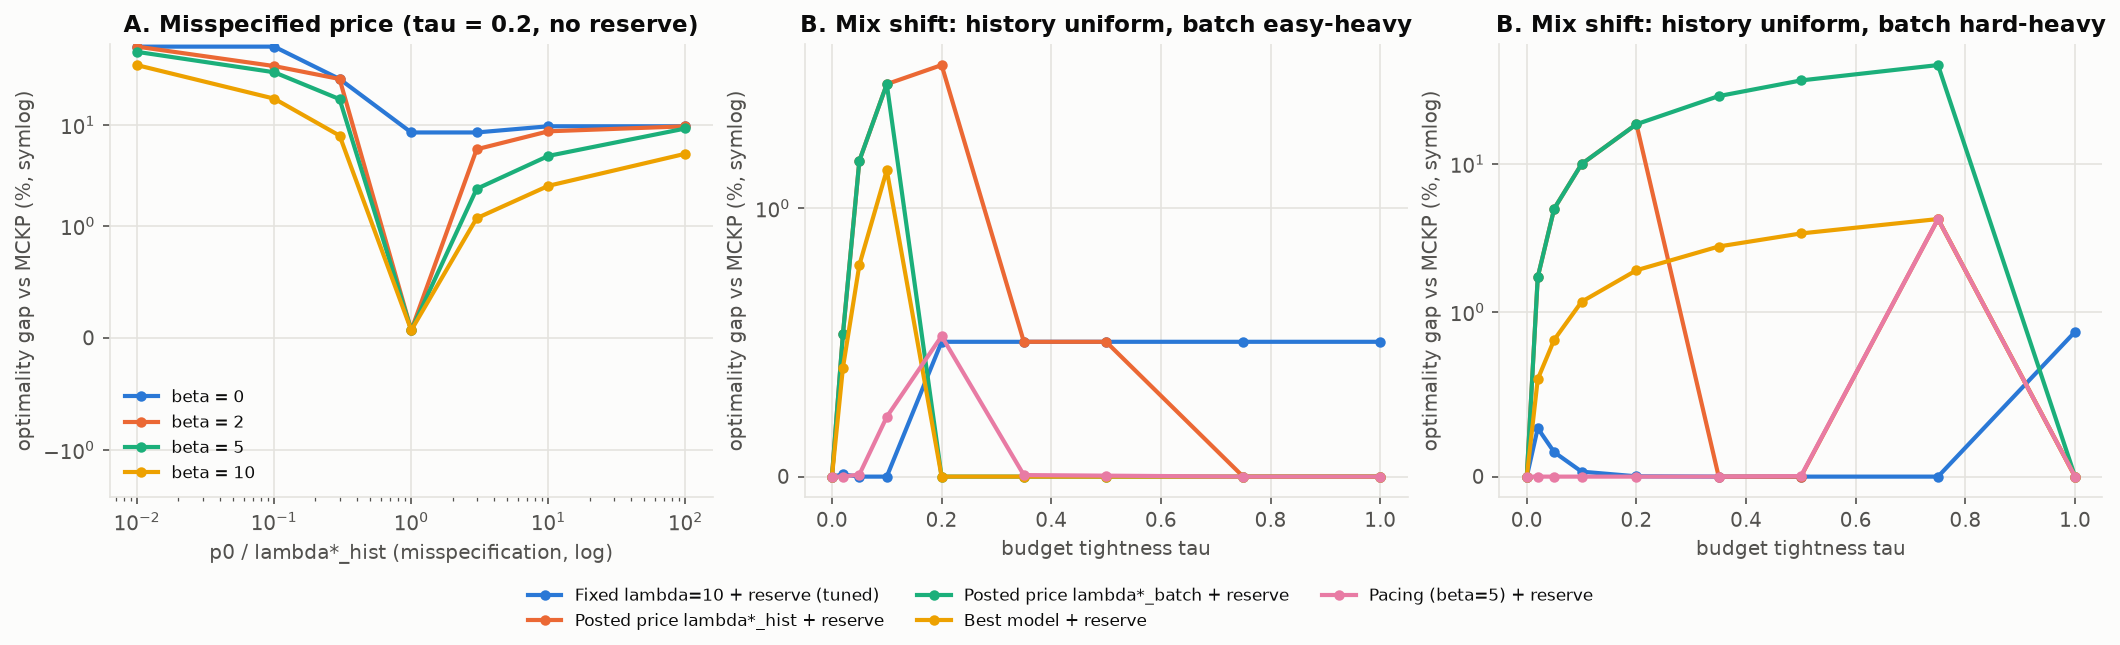

In [8]:
display(Image('experiments/figures/e05_pacing_robustness.png'))

## E6 - Factorial: 4 agent counts x 3 mixes x 5 budgets x 3 cost disparities (180 cells)

In [9]:
f = load('e06_summary')
agg = f.groupby('policy').agg(mean_gap=('gap_exp', 'mean'), worst_gap=('gap_exp', 'max'),
    gap_vs_serve_all=('gap_sa_exp', 'mean'), starve=('task_starve', 'mean'), jain=('jain_exp', 'mean'))
(agg.sort_values('mean_gap') * [100, 100, 100, 100, 1]).round(2)

,mean_gap,worst_gap,gap_vs_serve_all,starve,jain
policy,,,,,
MCKP (optimal),0.00,0.00,-2.25,4.03,0.95
Pacing + reserve + abstain (ours),0.71,6.76,-1.48,5.14,0.94
Static equal quota,1.51,7.25,-0.66,3.10,0.94
MCKP (serve all),1.85,24.45,0.00,0.00,0.94
Predictive router,1.96,24.45,0.11,0.00,0.94
Pacing + reserve (ours),2.08,24.45,0.23,0.00,0.94
U1 quasi-linear (lambda=10) + reserve,2.42,24.45,0.58,0.00,0.94
"U2 shadow price (p0=3, a=0.5) + reserve",2.52,24.45,0.68,0.00,0.94
Best model + reserve,2.76,24.45,0.93,0.00,0.94


**Decomposition of the residual gap.** Against the best allocation that serves every agent (`MCKP (serve all)`), pacing + reserve is within 0.23% on average; the rest of its 2.1% gap to MCKP is the *sacrifice gap*: under flat pricing the optimum refuses service to low-value hard tasks to fund R1 elsewhere. Letting agents abstain when their surplus at the current price is negative recovers most of it (0.7% mean gap).

In [10]:
for key in ('N', 'mix', 'tau', 'pricing'):
    display((100 * f[f.policy.isin(['Best model', 'Best model + reserve', 'Pacing + reserve (ours)', 'Pacing + reserve + abstain (ours)', 'Predictive router', 'MCKP (serve all)'])].pivot_table(index='policy', columns=key, values='gap_exp')).round(2))

N,5,10,20,50
policy,,,,
Best model,18.74,25.56,28.22,30.53
Best model + reserve,2.57,2.75,2.83,2.89
MCKP (serve all),1.77,1.85,1.89,1.89
Pacing + reserve (ours),2.17,2.11,2.03,2.01
Pacing + reserve + abstain (ours),0.94,0.69,0.62,0.60
Predictive router,2.03,1.98,1.92,1.91


mix,easy_heavy,hard_heavy,uniform
policy,,,
Best model,14.86,29.71,32.72
Best model + reserve,0.26,5.61,2.42
MCKP (serve all),0.11,4.65,0.80
Pacing + reserve (ours),0.24,5.01,0.99
Pacing + reserve + abstain (ours),0.41,1.19,0.55
Predictive router,0.11,4.91,0.85


tau,0.00,0.05,0.20,0.50,1.00
policy,,,,,
Best model,48.46,47.81,23.77,8.78,-0.00
Best model + reserve,3.48,3.72,3.82,2.79,-0.00
MCKP (serve all),3.48,2.97,2.01,0.80,0.00
Pacing + reserve (ours),3.48,3.04,2.57,1.02,0.29
Pacing + reserve + abstain (ours),1.28,0.87,0.91,0.23,0.29
Predictive router,3.48,3.04,2.40,0.87,0.00


pricing,flat2x,measured,steep10x
policy,,,
Best model,12.41,30.29,34.59
Best model + reserve,6.35,0.94,1.00
MCKP (serve all),5.49,0.00,0.06
Pacing + reserve (ours),5.76,0.20,0.28
Pacing + reserve + abstain (ours),1.29,0.33,0.52
Predictive router,5.61,0.10,0.17


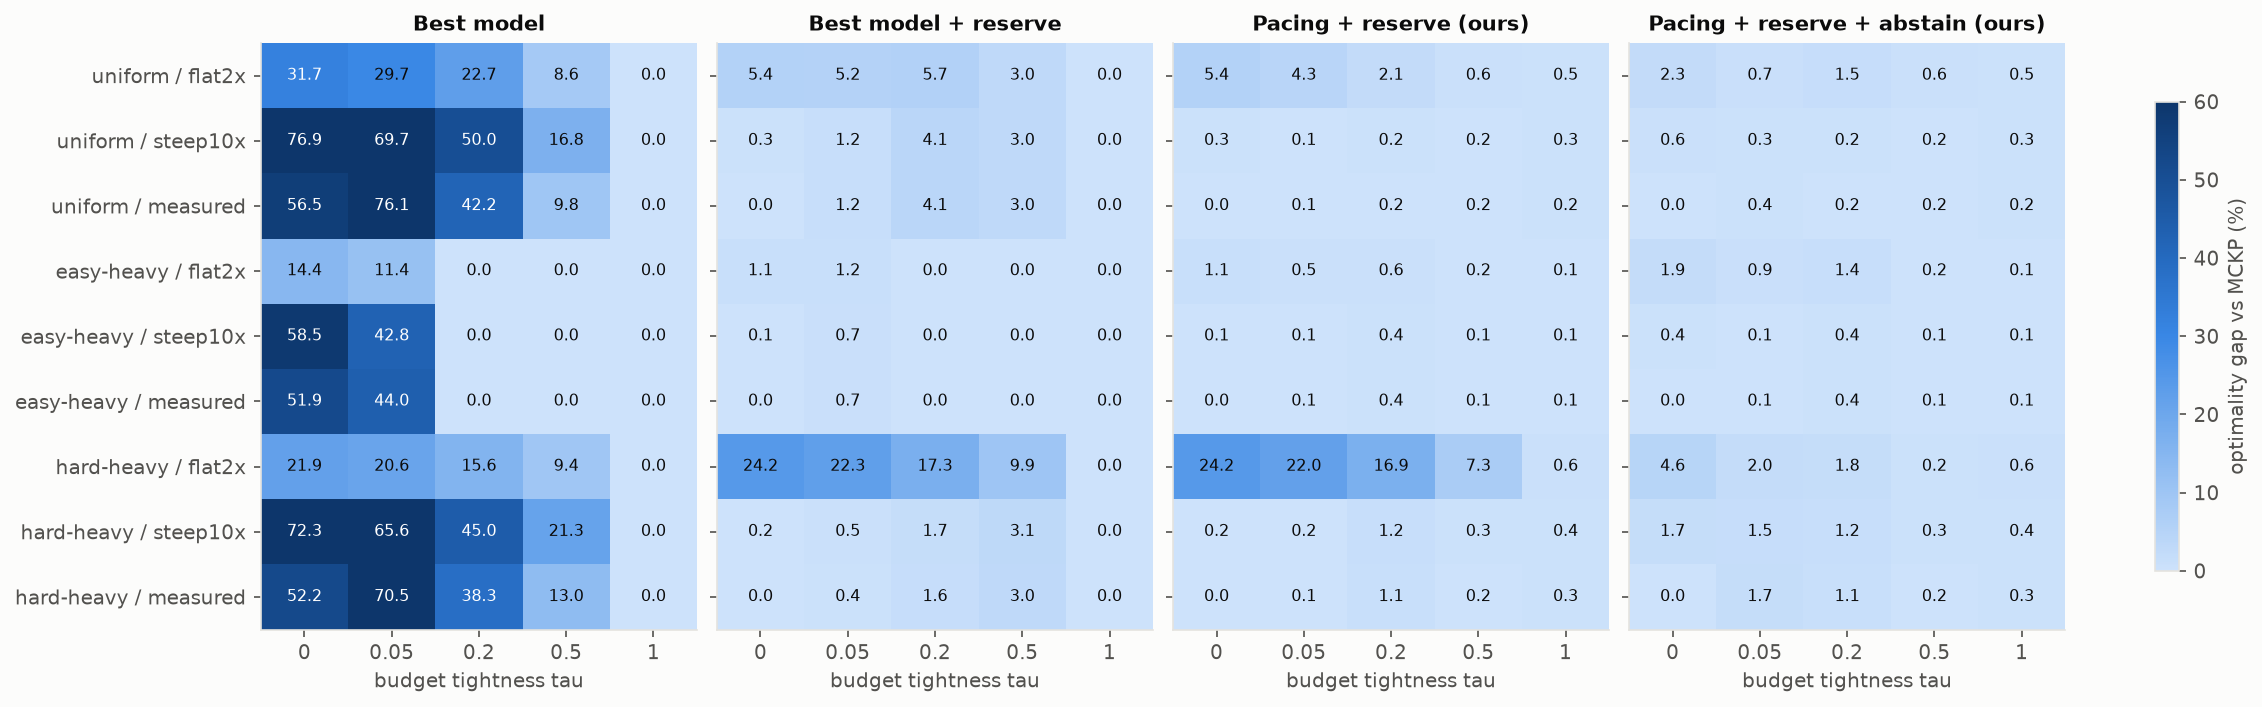

In [11]:
display(Image('experiments/figures/e06_factorial_heatmap.png'))

In [12]:
nh = load('e06b_summary')
(100 * nh.groupby('policy').gap_exp.agg(['mean', 'max'])).round(2)

,mean,max
policy,,
Cheapest model,12.93,49.30
MCKP (optimal),0.00,0.00
MCKP (serve all),1.85,24.45
Pacing + reserve (no price history),2.06,24.45
Pacing + reserve (ours),2.08,24.45
Pacing + reserve + abstain (no price history),1.07,24.45
Pacing + reserve + abstain (ours),0.71,6.76


The historical price only matters with abstention: plain pacing + reserve does as well starting from the floor price alone.

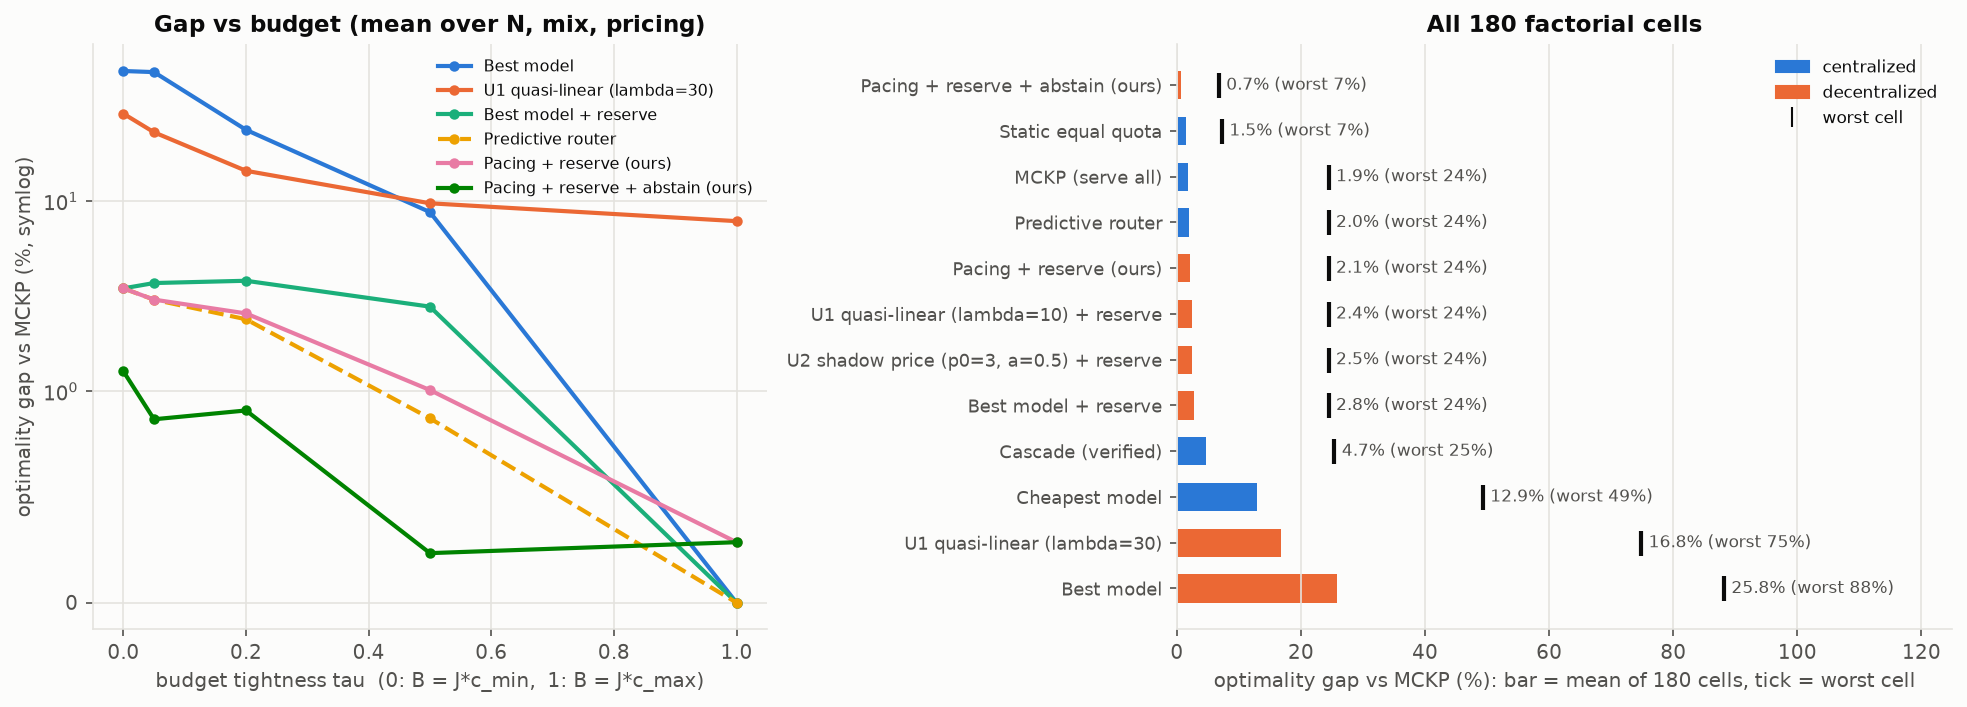

In [13]:
display(Image('experiments/figures/headline.png'))